In [1]:
import requests, numpy as np, pandas as pd
from PIL import Image
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
print("all good")

all good


In [6]:
import requests
import tarfile
import json
from pathlib import Path

archive_path = Path("artic-api-data.tar.bz2")
dataset_url = (
    "https://artic-api-data.s3.amazonaws.com/"
    "artic-api-data.tar.bz2"
)

# Save the download so rerunning this cell doesn't download it again.
if not archive_path.exists():
    print("Downloading the museum dataset. This may take a few minutes...")
    temporary_path = archive_path.with_suffix(".part")

    with requests.get(
        dataset_url, stream=True, timeout=(15, 120)
    ) as response:
        response.raise_for_status()

        with temporary_path.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    temporary_path.replace(archive_path)

print("Looking for Monet artworks...")

paintings = []

with tarfile.open(archive_path, mode="r|bz2") as archive:
    for member in archive:
        if not member.isfile():
            continue

        # Ignore records for artists, exhibitions, and other resources.
        if (
            "/artworks/" not in "/" + member.name
            or not member.name.endswith(".json")
        ):
            continue

        with archive.extractfile(member) as file:
            artwork = json.load(file)

        if (
            artwork.get("artist_title") == "Claude Monet"
            and artwork.get("image_id")
            and artwork.get("is_public_domain")
            and artwork.get("date_start") is not None
        ):
            paintings.append(artwork)

paintings.sort(key=lambda p: (p["date_start"], p["id"]))

print(f"\nFound {len(paintings)} usable Monet artworks.")

for painting in paintings[:5]:
    print(painting["date_start"], "—", painting["title"])

Looking for Monet artworks...

Found 46 usable Monet artworks.
1855 — Caricature of a Man with a Big Cigar
1855 — Caricature of a Man in the Small Hat
1855 — Caricature of Auguste Vacquerie
1855 — Caricature of a Man Standing by Desk (recto); Sketch of Male Head in Profile (verso)
1855 — Caricature of a Man with a Large Nose


In [7]:
# Keep paintings, excluding drawings and caricatures.
monet_paintings = [
    p for p in paintings
    if (p.get("artwork_type_title") or "").lower() == "painting"
]

print(f"Found {len(monet_paintings)} paintings.")

for p in monet_paintings[:5]:
    print(p["date_start"], "—", p["title"])

Found 33 paintings.
1867 — The Beach at Sainte-Adresse
1868 — On the Bank of the Seine, Bennecourt
1873 — The Artist's House at Argenteuil
1877 — Arrival of the Normandy Train, Gare Saint-Lazare
1880 — Apples and Grapes


In [9]:
first = monet_paintings[0]
print(first["title"])
print(f"https://www.artic.edu/artworks/{first['id']}")

The Beach at Sainte-Adresse
https://www.artic.edu/artworks/14598


Saving default.jpg to default.jpg


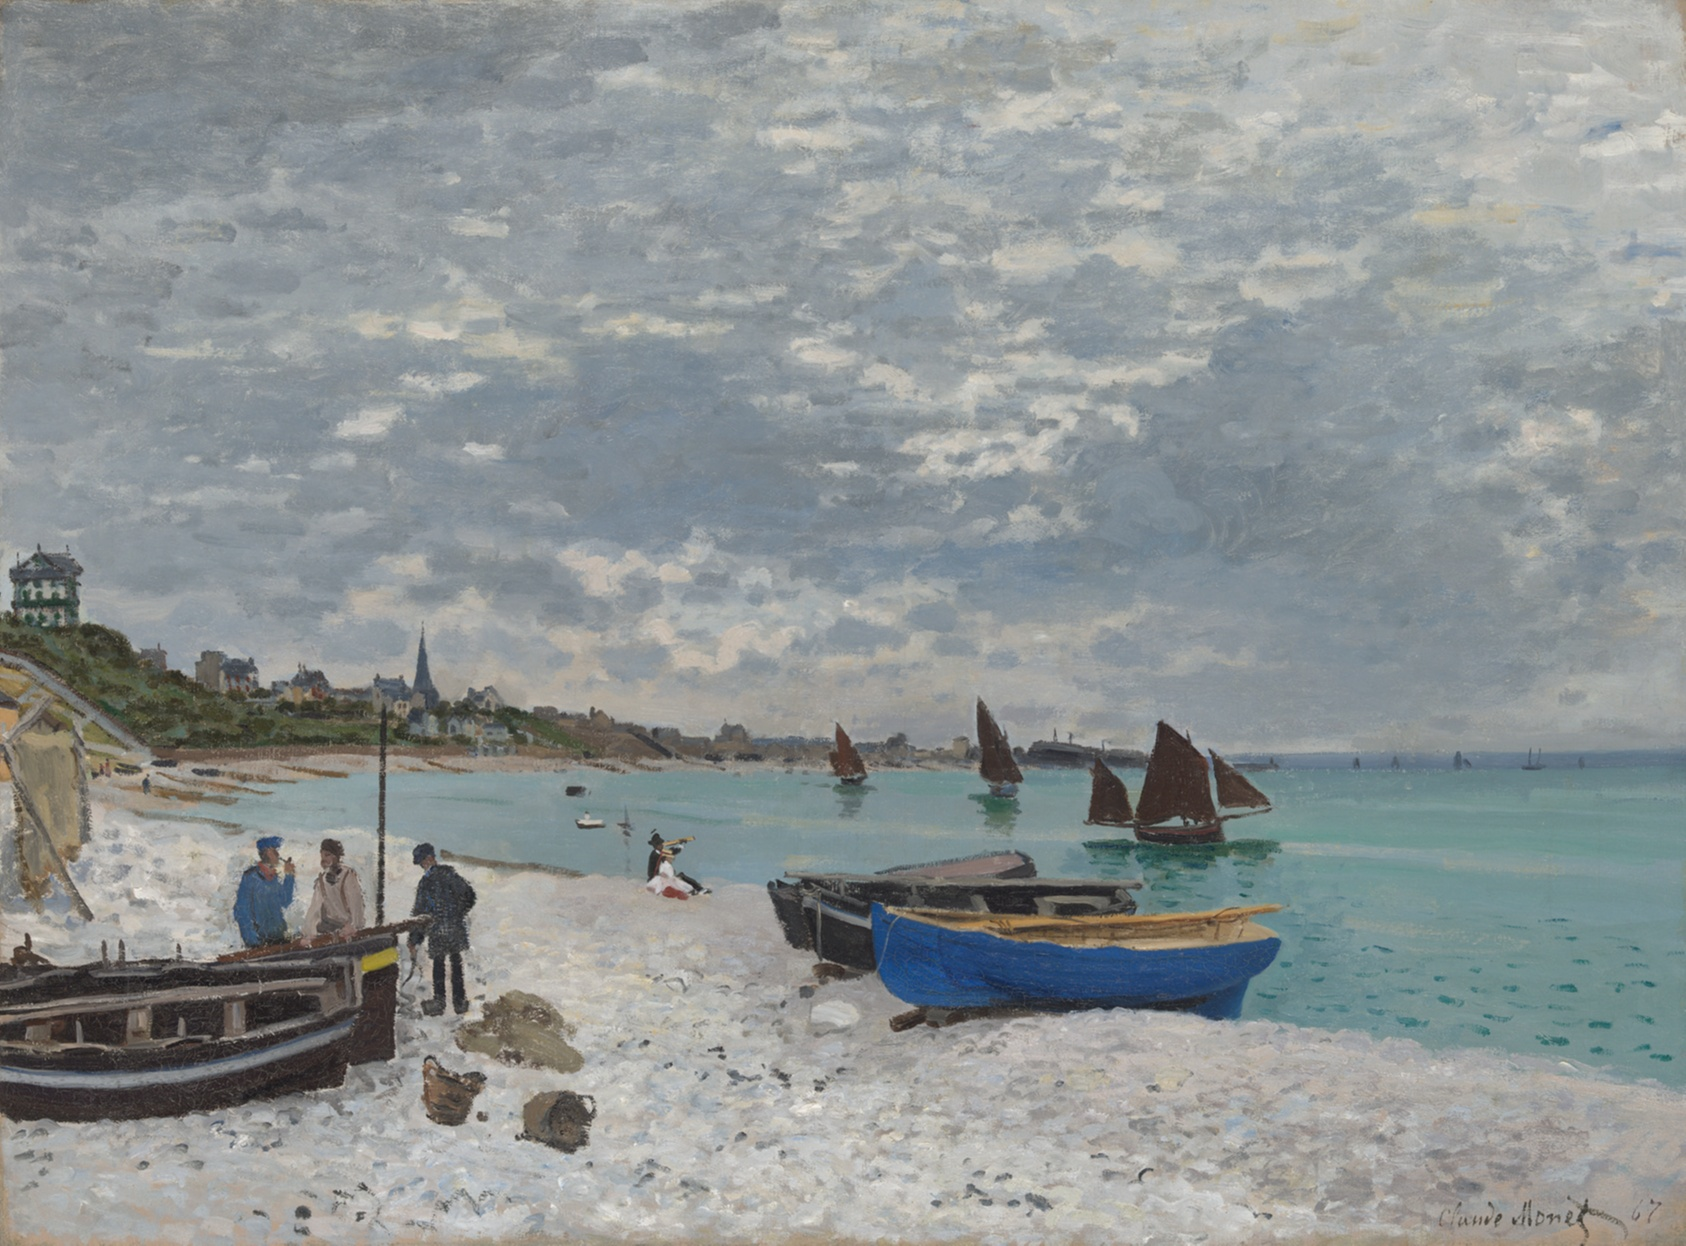

In [10]:
from google.colab import files
from PIL import Image
from io import BytesIO
from IPython.display import display

uploaded = files.upload()

filename = next(iter(uploaded))
first_image = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

display(first_image)

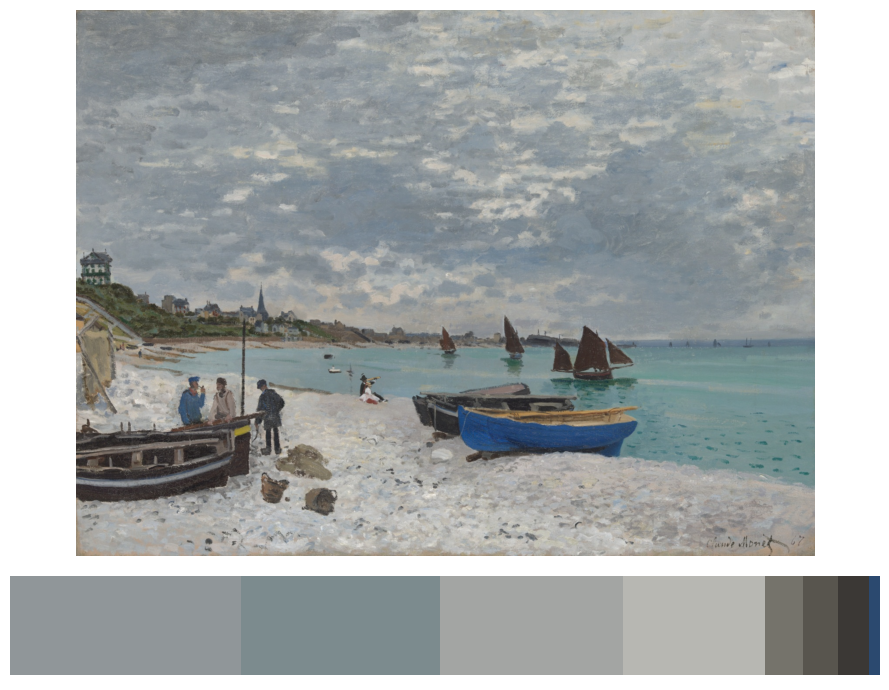

#909699: 26.6%
#7c8b8e: 22.8%
#a3a5a3: 21.1%
#b7b7b2: 16.2%
#75736b: 4.4%
#58554e: 3.9%
#3b3835: 3.7%
#2b496f: 1.2%


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Shrink a copy while preserving the painting's proportions.
small = first_image.copy()
small.thumbnail((200, 200))

# Turn the image into a list of RGB pixel colors.
pixels = np.asarray(small).reshape(-1, 3)

# Group similar colors into five clusters.
model = KMeans(n_clusters=8, n_init=10, random_state=0)
model.fit(pixels)

# Sort colors by how much of the image they represent.
counts = np.bincount(model.labels_, minlength=8)
order = np.argsort(-counts)

palette = np.clip(
    np.rint(model.cluster_centers_[order]), 0, 255
).astype("uint8")

proportions = counts[order] / counts.sum()

# Show the painting and its palette.
fig, (art_ax, palette_ax) = plt.subplots(
    2, 1, figsize=(9, 7),
    gridspec_kw={"height_ratios": [5, 1]}
)

art_ax.imshow(first_image)
art_ax.axis("off")

left = 0
for color, proportion in zip(palette, proportions):
    palette_ax.barh(
        0, proportion, left=left,
        color=color / 255, height=1
    )
    left += proportion

palette_ax.set_xlim(0, 1)
palette_ax.axis("off")

plt.tight_layout()
plt.savefig("first_monet_palette.png", dpi=200, bbox_inches="tight")
plt.show()

for color, proportion in zip(palette, proportions):
    hex_color = "#" + "".join(f"{int(c):02x}" for c in color)
    print(f"{hex_color}: {proportion:.1%}")